# Imports

In [ ]:
%load_ext autoreload
%autoreload 2

import sys
sys.path.append('..') # path to the root directory
sys.path.append('../..') # path to the root directory
sys.path.append('../../src') # path to the src directory

# Change these lines to match your local directory structure
# sys.path.append('/Users/xz498/Library/CloudStorage/OneDrive-DrexelUniversity/Chang Lab - Documents/General/Individual/Xinqiao Zhang/data_analysis/ultrasonicTesting/')
sys.path.append('/Users/xz498/Library/CloudStorage/OneDrive-DrexelUniversity/Chang Lab - Documents/General/Individual/Xinqiao Zhang/data_analysis/ultrasonic_ml/src/')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

## Import Data

AcousticDatabase contains methods to open sqlite file, convert parameters from dict to hdf5 attr friendly format, and setup groups and datasets for raw and preprocessed. Does not contain methods for indexing and retrieving data. These will be specific to the type of experiment we have.

AcousticScanDatabase inhereits from AcousticDatabase. Inherits setup and filing functions for raw and preprocessed. Write your own indexing and filling methods.

In [ ]:
# load the database class
import ultrasonic_ml.data.acoustic_datasets as db
import math
from pathlib import Path

# NOTE: make sure this is only open in one notebook at a time, otherwise the database will be locked and you will not be able to access it.
filepath = '091626_singleroll_scan_1mm_multiplexer.sqlite3' 
p = Path(filepath)

save_folder = '/Users/xz498/Library/CloudStorage/OneDrive-DrexelUniversity/Chang Lab - Documents/General/Individual/Xinqiao Zhang/data_analysis/ultrasonic_ml/Notebooks/fft'

database = db.AcousticScanDatabaseFFT(save_folder=save_folder, 
                                      h5_name='091626_singleroll_scan_1mm_multiplexer.h5', 
                                      sqlite_path=filepath)

Establishing SQLite connection to database...
Loading h5 parameters...
	Finished.


In [ ]:
# # Look at sqlite database structure if you want
# database.print_sqlite_schema()

In [ ]:
# # Run ONCE
# # setup and fill the raw data group from sqlite file. 
# #TODO: experimentally check that primary and 2ndary axis steps are correc
# #TODO: sop to always take picture of setup when running UT
# database.sqlite_to_h5()

In [ ]:
# # look at parameter setup if you want
# database.print_parameters()

{   'autoRange': {'description': '', 'value': 'False'},
    'autoRangeEcho': {'description': '', 'value': 'False'},
    'collectionDirection': {   'description': 'forward/reverse/both',
                               'value': 'both'},
    'collectionMode': {   'description': 'transmission/echo/both',
                          'value': 'echo'},
    'dt': {'description': 'Sampling interval', 'unit': 's', 'value': 8e-09},
    'experiment': {   'description': "'move': move the transducers/ 'single "
                                     "pulse': perform a single test pulse/ "
                                     "'repeat pulse': repeat a pulse at a "
                                     'single location for a given time and '
                                     "frequency/ 'single scan': perform a "
                                     "single 2D scan/ 'multi scan': repeat a "
                                     "2D scan with a set frequency/ 'sweep': "
                                   

In [ ]:
# look at the h5 database structure
database.print_schema()

<HDF5 file "091626_singleroll_scan_1mm_multiplexer.h5" (mode r+)>
|--<HDF5 dataset "calculations": shape (2, 151, 31, 8556), type "<c8">
|--<HDF5 dataset "config_metadata": shape (), type "|O">
|--<HDF5 group "/fft_data" (1 members)>
|  |--<HDF5 dataset "calculations": shape (2, 151, 31, 8556), type "<c8">
|--<HDF5 group "/first_break_aligned" (2 members)>
|  |--<HDF5 dataset "hilbert": shape (2, 151, 31, 17111), type "<f4">
|  |--<HDF5 dataset "waveforms": shape (2, 151, 31, 17111), type "<f4">
|--<HDF5 group "/preprocessed_data" (2 members)>
|  |--<HDF5 dataset "hilbert": shape (2, 151, 31, 20000), type "<f4">
|  |--<HDF5 dataset "waveforms": shape (2, 151, 31, 20000), type "<f4">
|--<HDF5 group "/raw_data" (2 members)>
|  |--<HDF5 dataset "hilbert": shape (2, 151, 31, 20000), type "<f4">
|  |--<HDF5 dataset "waveforms": shape (2, 151, 31, 20000), type "<f4">


### Preprocessing

In [5]:
# # Run ONCE
# # setup and fill the preprocessed data group from raw data.
# database.write_preprocessed_data(apply_ungain = False, apply_filter=True, 
#                                  lower_fs_coeff = 1/250, upper_fs_coeff = 1/5, filter_order = 3)

In [8]:
# # Look at basic view of mean image and spectrum of raw data
# database.view_mean_img_plot(from_group='preprocessed_data')

### Match first break

In [ ]:
# # RUN ONCE
# # align forward and reverse waveforms to first break and save to h5.
# database.write_first_break_aligned_data(from_group='preprocessed_data')

Aligning first break: 9362it [00:17, 530.22it/s]                          

	Finished


/Users/xz498/Library/CloudStorage/OneDrive-DrexelUniversity/Chang Lab - Documents/General/Individual/Xinqiao Zhang/data_analysis/ultrasonic_ml/Notebooks/fft/../../src/ultrasonic_ml/data/acoustic_datasets.py:1160: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()


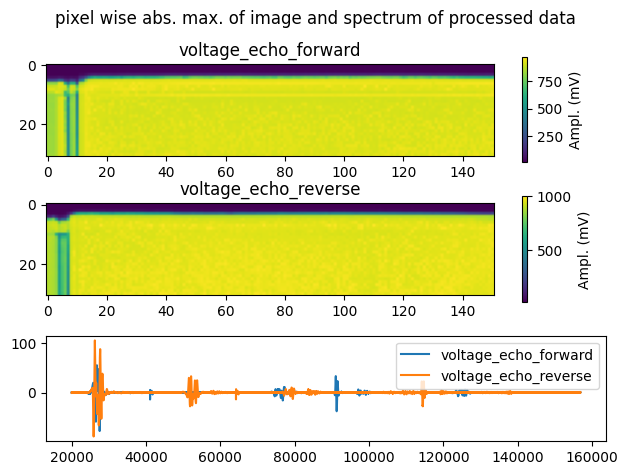

In [ ]:
# # Look at basic view of mean image and spectrum of raw data
# database.view_mean_img_plot(from_group='first_break_aligned')

### Calculate FFT

In [ ]:
# RUN ONCE
# align forward and reverse waveforms to first break and save to h5.
database.write_fft_data(from_group='first_break_aligned')

OSError: Unable to synchronously open file (file is already open for read-only)

<Figure size 640x480 with 0 Axes>

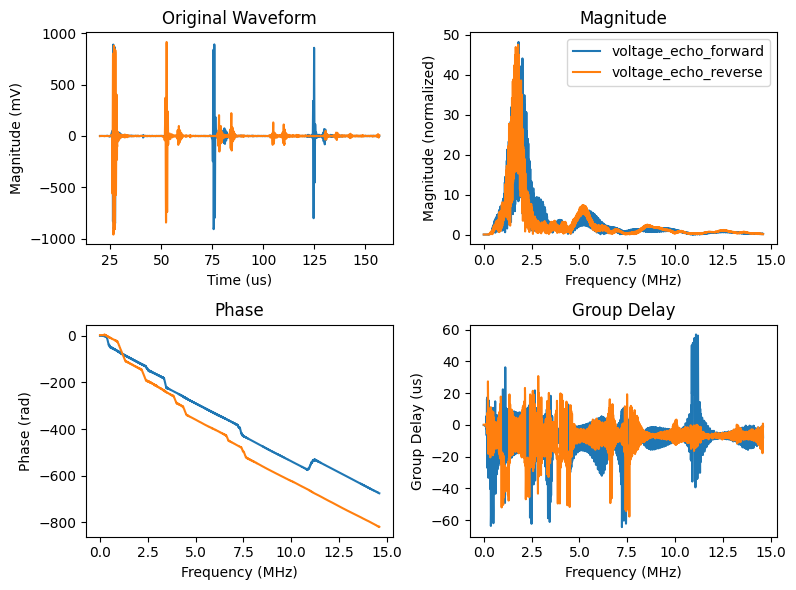

In [5]:
database.view_fft_plots(idx=(75,15), crop=[0, 2000], from_group='first_break_aligned') #TODO: check

## Interactive visualizer

In [6]:
from ultrasonic_ml.viz import acoustic_viewers as viz

viz.AcousticScanViewer.launch(db=database, from_group='first_break_aligned')

Launching server at http://localhost:55976
AcousticViewer closed and cache cleared.


In [ ]:
from ultrasonic_ml.viz import acoustic_viewers as viz

viz.AcousticScanViewerFFT.launch(db=database, from_group='first_break_aligned')

Launching server at http://localhost:59202


In [12]:
# Launch individually to test
from ultrasonic_ml.viz import acoustic_viewers as viz

visualizer = viz.AcousticScanViewerFFT(database, from_group='first_break_aligned')


Opening FFT datasets from group: first_break_aligned


In [ ]:
visualizer.

In [30]:
test = visualizer.db._angle( visualizer.fft_ds[1,...,500], )

In [62]:
gd = visualizer.db._group_delay( visualizer.phase, visualizer.freq[0:2000] )[1,...,500]

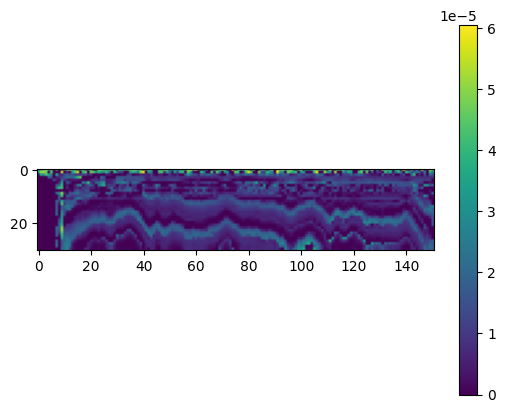

In [65]:
plt.imshow(gd.T, vmin=0)
plt.colorbar()

(array([  1.,   3.,   4.,   6.,   3.,   4.,  16.,  26.,  55.,  13.,   4.,
          7.,   4.,  10.,  11.,   4.,   7.,   4.,   7.,  10.,  15.,   9.,
          9.,  11.,  14.,   8.,  16.,  17.,   6.,  14.,   4.,  11.,  10.,
         15.,  13.,  17.,  20.,  20.,  23.,  20.,  22.,  25.,  35.,  49.,
         47.,  58.,  80.,  86., 130., 126., 152., 142., 119., 132., 124.,
        148., 154., 158., 212., 191., 204., 129., 139., 103.,  88.,  88.,
         86.,  96.,  72.,  62.,  71.,  63.,  59.,  75.,  58.,  72.,  61.,
         57.,  60.,  34.,  38.,  30.,  14.,  17.,  23.,  32.,  20.,  33.,
         23.,  35.,  34.,  13.,   6.,   4.,   3.,   3.,   6.,   4.,   1.,
          4.]),
 array([-3.20238770e+04, -3.13699668e+04, -3.07160586e+04, -3.00621484e+04,
        -2.94082383e+04, -2.87543281e+04, -2.81004199e+04, -2.74465098e+04,
        -2.67926016e+04, -2.61386914e+04, -2.54847812e+04, -2.48308711e+04,
        -2.41769629e+04, -2.35230527e+04, -2.28691445e+04, -2.22152344e+04,
        -2.156

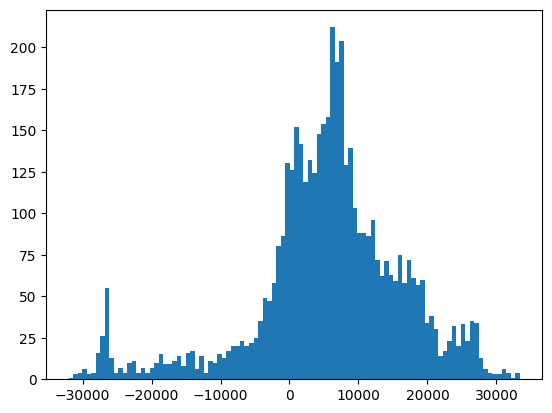

In [61]:
plt.hist(gd.T.flatten()/2e-9, bins=100)

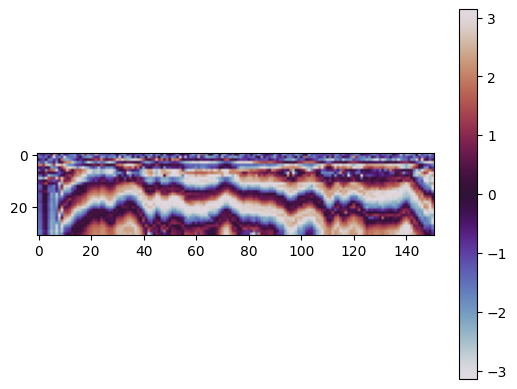

In [43]:
plt.imshow(test.T,cmap='twilight')
plt.colorbar(cmap='twilight')

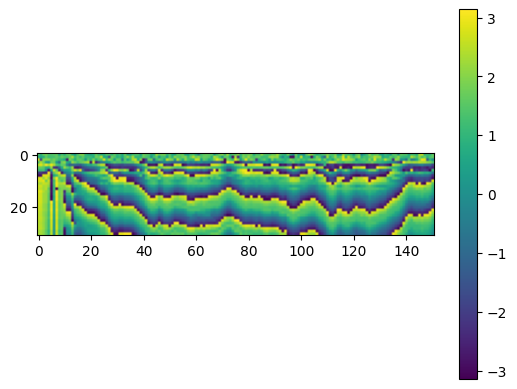

In [29]:
plt.imshow(test.T)
plt.colorbar()

In [23]:
mag = visualizer.get_2d_slice( w=0, y=500, dataset='phase')

In [19]:
mag.shape

(151, 31)

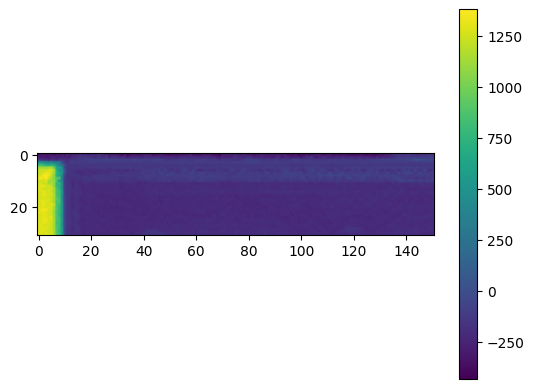

In [21]:
plt.imshow(mag.T)
plt.colorbar()

In [ ]:
app = visualizer.create_dashboard()
app.show()

In [9]:
debug

    [... skipping 1 hidden frame(s)]
  /var/folders/vg/g8h80y317zj5sfz8_f4l85wddxx210/T/ipykernel_4699/1378570762.py(4)<module>()
      2 from ultrasonic_ml.viz import acoustic_viewers as viz
      3 
----> 4 visualizer = viz.AcousticScanViewerFFT(database, from_group='first_break_aligned')
      5 app = visualizer.create_dashboard()
      6 app.show()
> /Users/xz498/Library/CloudStorage/OneDrive-DrexelUniversity/Chang Lab - Documents/General/Individual/Xinqiao Zhang/data_analysis/ultrasonic_ml/src/ultrasonic_ml/viz/acoustic_viewers.py(3)__init__()
      1 import h5py
      2 import numpy as np
----> 3 from functools import lru_cache
      4 
      5 import param

*** AttributeError: 'AcousticScanViewerFFT' object has no attribute 'db'
*** AttributeError: 'AcousticScanViewerFFT' object has no attribute 'db'
